<a href="https://colab.research.google.com/github/eholmes877/PythonGIS/blob/main/GeoPython2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip install geojson

In [3]:
import pandas
import matplotlib
import geopandas
import geojson
import folium

In [4]:
from shapely.geometry import Point

In [5]:
# Create 'Point' objects
point1 = Point(2.2, 4.2)
point2 = Point(7.2, -25.1)
point3 = Point(9.26, -2.456)
point4_3D = Point(9.26, -2.456, 0.57)

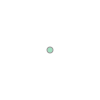

In [6]:
point1

In [7]:
dist = point1.distance(point2)
print(f"Distance between the points is {dist:.2f} units")

Distance between the points is 29.72 units


Import the LineString Class

In [8]:
from shapely.geometry import LineString

# Create a LineString from our Point objects
line = LineString([point1, point2, point3])

Create a LineString from a list of coordinates: (with the same coordinate values as the points, so resulats should be identical)

In [9]:
line2 = LineString([(2.2, 4.2), (7.2, -25.1), (9.26, -2.456)])

In [10]:
# Check if the lines are indeed identical
line == line2

True

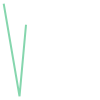

In [11]:
line

In [12]:
print(line)

LINESTRING (2.2 4.2, 7.2 -25.1, 9.26 -2.456)


In [13]:
type(line)

shapely.geometry.linestring.LineString

In [14]:
line.geom_type

'LineString'

Get coordinate tuples

In [15]:
list(line.coords)

[(2.2, 4.2), (7.2, -25.1), (9.26, -2.456)]

In [16]:
xcoords = list(line.xy[0])
ycoords = list(line.xy[1])

print(xcoords)
print(ycoords)

[2.2, 7.2, 9.26]
[4.2, -25.1, -2.456]


Get the length of the line

In [17]:
line_length = line.length
print(f"Length of our line: {line_length:.1f} units")

Length of our line: 52.5 units


Get the centre point of the line

In [18]:
print(line.centroid)

POINT (6.229961354035622 -11.892411157572392)


**Polygons**

In [19]:
from shapely.geometry import Polygon

# Create a Polygon from the coordinates
polygon1 = Polygon([(2.2, 4.2), (7.2, -25.1), (9.26, -2.456)])

In [20]:
polygon2 = Polygon([point1, point2, point3])

In [21]:
from shapely.geometry import LinearRing

shell = LinearRing([point1, point2, point3, point1])
polygon3 = Polygon(shell)

In [22]:
polygon1 == polygon2 == polygon3

True

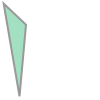

In [23]:
polygon1

In [24]:
print(polygon1)

POLYGON ((2.2 4.2, 7.2 -25.1, 9.26 -2.456, 2.2 4.2))


In [25]:
# Data type
type(polygon1)

shapely.geometry.polygon.Polygon

In [27]:
# Geometry type
polygon1.geom_type

'Polygon'

In [28]:
help(Polygon)

Help on class Polygon in module shapely.geometry.polygon:

class Polygon(shapely.geometry.base.BaseGeometry)
 |  Polygon(shell=None, holes=None)
 |
 |  A geometry type representing an area that is enclosed by a linear ring.
 |
 |  A polygon is a two-dimensional feature and has a non-zero area. It may
 |  have one or more negative-space "holes" which are also bounded by linear
 |  rings. If any rings cross each other, the feature is invalid and
 |  operations on it may fail.
 |
 |  Parameters
 |  ----------
 |  shell : sequence
 |      A sequence of (x, y [,z]) numeric coordinate pairs or triples, or
 |      an array-like with shape (N, 2) or (N, 3).
 |      Also can be a sequence of Point objects.
 |  holes : sequence
 |      A sequence of objects which satisfy the same requirements as the
 |      shell parameters above
 |
 |  Attributes
 |  ----------
 |  exterior : LinearRing
 |      The ring which bounds the positive space of the polygon.
 |  interiors : sequence
 |      A sequence 

In [29]:
# define the exterior
outer = LinearRing([(-180, 90), (-180, -90), (180, -90), (180, 90)])

# define a hole:
hole = LinearRing([(-170, 80), (-100, -80), (100, -80), (170, 80)])

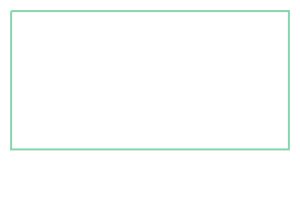

In [30]:
outer

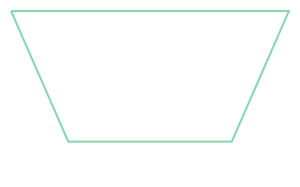

In [31]:
hole

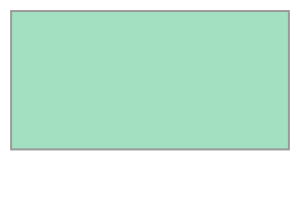

In [32]:
polygon_without_hole = Polygon(outer)
polygon_without_hole

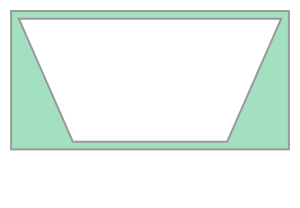

In [33]:
polygon_with_hole = Polygon(outer, [hole])
polygon_with_hole

In [34]:
print(polygon_without_hole)
print(polygon_with_hole)

POLYGON ((-180 90, -180 -90, 180 -90, 180 90, -180 90))
POLYGON ((-180 90, -180 -90, 180 -90, 180 90, -180 90), (-170 80, -100 -80, 100 -80, 170 80, -170 80))


Polygon properties and methods

In [35]:
print(f"Polygon centroid: {polygon_with_hole.centroid}")
print(f"Polygon area: {polygon_with_hole.area}")
print(f"Polygon bounding box: {polygon_with_hole.bounds}")
print(f"Polygon exterior ring: {polygon_with_hole.exterior}")
print(f"Polygon circumference: {polygon_with_hole.exterior.length}")

Polygon centroid: POINT (0 -13.827160493827162)
Polygon area: 21600.0
Polygon bounding box: (-180.0, -90.0, 180.0, 90.0)
Polygon exterior ring: LINEARRING (-180 90, -180 -90, 180 -90, 180 90, -180 90)
Polygon circumference: 1080.0


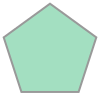

In [36]:
pentagon = Polygon([(30, 2.01), (31.91, 0.62), (31.18, -1.63), (28.82, -1.63), (28.09, 0.62)])
pentagon

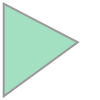

In [40]:
triangle1 = Polygon([(26, 2.5), (30, 0.42), (26, -2.5)])
triangle1

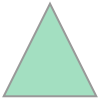

In [49]:
triangle2 = Polygon([(0,0), (2,4), (4,0)])
triangle2

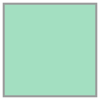

In [48]:
square = Polygon([(0, 0), (0, 15), (15, 15), (15, 0)])
square

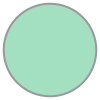

In [50]:
# Circle
point = Point((0,0))
point.buffer(1)

**Geometry Collections**

In [51]:
from shapely.geometry import MultiPoint, MultiLineString, MultiPolygon

# Create a MultiPoint object of our points 1,2 and 3
multipoint = MultiPoint([point1, point2, point3])

# We can also create a MultiLineString with two lines
line1 = LineString([point1, point2])
line2 = LineString([point2, point3])
multiline = MultiLineString([line1, line2])

print(multipoint)
print(multiline)

MULTIPOINT ((2.2 4.2), (7.2 -25.1), (9.26 -2.456))
MULTILINESTRING ((2.2 4.2, 7.2 -25.1), (7.2 -25.1, 9.26 -2.456))


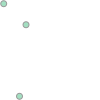

In [52]:
multipoint

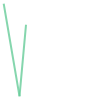

In [53]:
multiline

POLYGON ((-180 90, -180 -90, 0 -90, 0 90, -180 90))


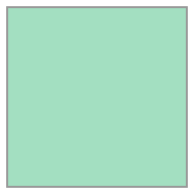

In [54]:
western_hemisphere = Polygon([(-180, 90), (-180, -90), (0, -90), (0, 90)])
print(western_hemisphere)
western_hemisphere

POLYGON ((180 -90, 180 90, 0 90, 0 -90, 180 -90))


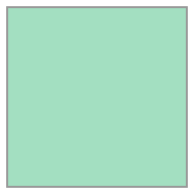

In [55]:
from shapely.geometry import box
min_x = 0
max_x = 180
min_y = -90
max_y = 90

eastern_hemisphere = box(min_x, min_y, max_x, max_y)

print(eastern_hemisphere)
eastern_hemisphere

MULTIPOLYGON (((-180 90, -180 -90, 0 -90, 0 90, -180 90)), ((180 -90, 180 90, 0 90, 0 -90, 180 -90)))


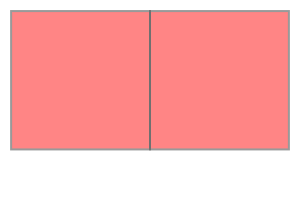

In [56]:
# Let's create our MultiPolygon.
# Pass multiple Polygon objects as a list
multipolygon = MultiPolygon([western_hemisphere, eastern_hemisphere])

print(multipolygon)
multipolygon

**Convex hull and envelope**

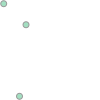

In [57]:
# Check input geometry
multipoint

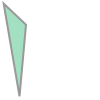

In [58]:
# Convex Hull
multipoint.convex_hull

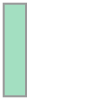

In [59]:
# Envelope (small rectangular polygon around a geometry/set of geometries):
multipoint.envelope

In [60]:
# Validity of geometries
print(f"Is polygon valid?: {polygon_with_hole.is_valid}")

Is polygon valid?: True
